# 04 · Events: did patches and controversies move the reviews?

Marks key dates (launches, big updates, controversies, store changes) on each game's timeline and measures how the share of thumbs-up reviews changed around each one.

**Input:** `data/processed/reviews_clean.csv` and `data/events.csv` (editable: add, fix or remove events)  
**Output:** `data/processed/event_impact.csv` and charts in `images/`

**Important limitation, checked in section 1.** The scraper kept at most 800 reviews per game per month, newest first. In busy months that means the sample covers only the *last days* of the month, not the whole month. Section 1 measures this, and the event tables report how many days around each event actually have data, so unreliable comparisons are flagged instead of hidden.

In [11]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

DATA = Path("../data")
PROC = DATA / "processed"
IMG = Path("../images")
IMG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

CAP = 800  # the per-game, per-month cap used by the scraper

df = pd.read_csv(PROC / "reviews_clean.csv", parse_dates=["month"])
df["created_utc"] = pd.to_datetime(df["created_utc"], utc=True)
df["day"] = df["created_utc"].dt.floor("D")

events = pd.read_csv(DATA / "events.csv")
events["date"] = pd.to_datetime(events["date"], utc=True)
events = events[events["game"].isin(df["game"].unique())].sort_values(["game", "date"]).reset_index(drop=True)

print(f"{len(df):,} reviews | {df['game'].nunique()} games | {len(events)} events")
events[["game", "date", "category", "label", "verified"]].assign(date=lambda x: x["date"].dt.date)

298,001 reviews | 5 games | 29 events


,game,date,category,label,verified
0,Battlefield 2042,2021-11-19,launch,Launch,memory
1,Battlefield 2042,2022-06-09,update,Season 1: Zero Hour,memory
2,Battlefield 2042,2025-05-27,controversy,Patch 8.8: Secure Boot required on supported systems,yes
3,Battlefield 2042,2025-08-07,controversy,Review bombing accelerates (Battlefield 6 Secure Boot news),approx
4,Battlefield 2042,2025-10-10,launch,Battlefield 6 launches,memory
5,Cyberpunk 2077,2020-12-10,launch,"Launch (PC, PS4, Xbox One)",yes
6,Cyberpunk 2077,2020-12-17,store,Removed from PlayStation Store,approx
7,Cyberpunk 2077,2021-03-15,update,First major patch (1.2),approx
8,Cyberpunk 2077,2021-06-21,store,Returns to PlayStation Store,yes
9,Cyberpunk 2077,2022-02-15,update,Next-gen console update,approx


## 1. How well does the sample cover each month?

For every game-month: how many reviews, and across how many days they are spread. A month at the cap with a short span means we only saw its last days.

In [12]:
cov = (df.groupby(["game", "month"])
         .agg(n=("recommended", "size"), first=("created_utc", "min"), last=("created_utc", "max"))
         .reset_index())
cov["span_days"] = (cov["last"] - cov["first"]).dt.days + 1
cov["at_cap"] = cov["n"] >= 0.95 * CAP

coverage = (cov.groupby("game")
              .apply(lambda g: pd.Series({
                  "months": len(g),
                  "months_at_cap_%": round(100 * g["at_cap"].mean()),
                  "median_span_days_when_capped": g.loc[g["at_cap"], "span_days"].median(),
                  "median_span_days_not_capped": g.loc[~g["at_cap"], "span_days"].median(),
              }), include_groups=False))
coverage

,months,months_at_cap_%,median_span_days_when_capped,median_span_days_not_capped
game,,,,
Battlefield 2042,60.0,70.0,18.0,30.0
Cyberpunk 2077,71.0,89.0,7.0,7.0
Helldivers 2,33.0,88.0,5.0,6.0
No Man's Sky,123.0,76.0,16.0,30.0
Stardew Valley,129.0,84.0,7.0,30.0


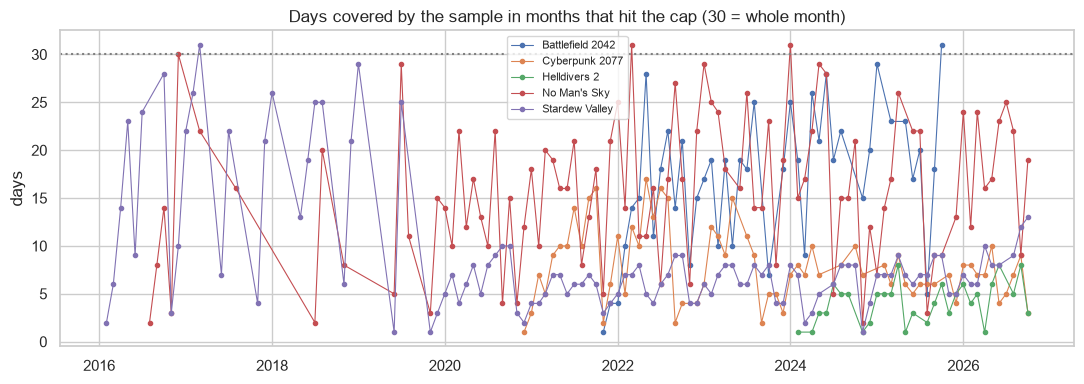

In [13]:
capped = cov[cov["at_cap"]]
if capped.empty:
    print("No month hit the cap, so every month is fully covered.")
else:
    fig, ax = plt.subplots(figsize=(11, 4))
    for game, g in capped.groupby("game"):
        ax.plot(g["month"], g["span_days"], marker="o", ms=3, lw=0.8, label=game)
    ax.set(title="Days covered by the sample in months that hit the cap (30 = whole month)", xlabel="", ylabel="days")
    ax.axhline(30, color="gray", ls=":")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(IMG / "sample_coverage.png", dpi=150)
    plt.show()

**How to read this:** if a game's capped months cover only a few days, a month's thumbs-up share describes the *end* of that month. That is fine for long trends (years), but it can miss an event in the middle of a month. If coverage is poor for the games you care about, re-collect those games with weekly windows.

## 2. Timeline with events

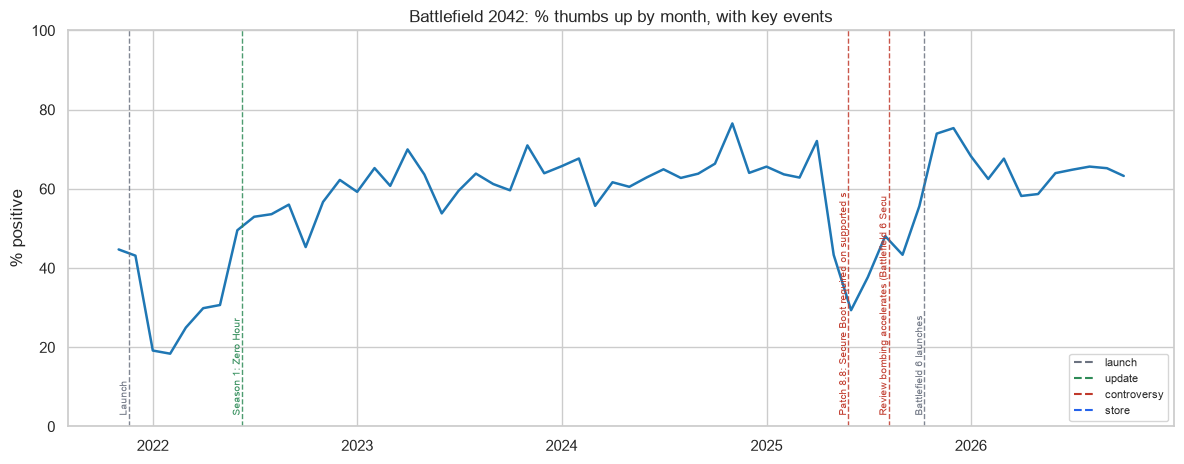

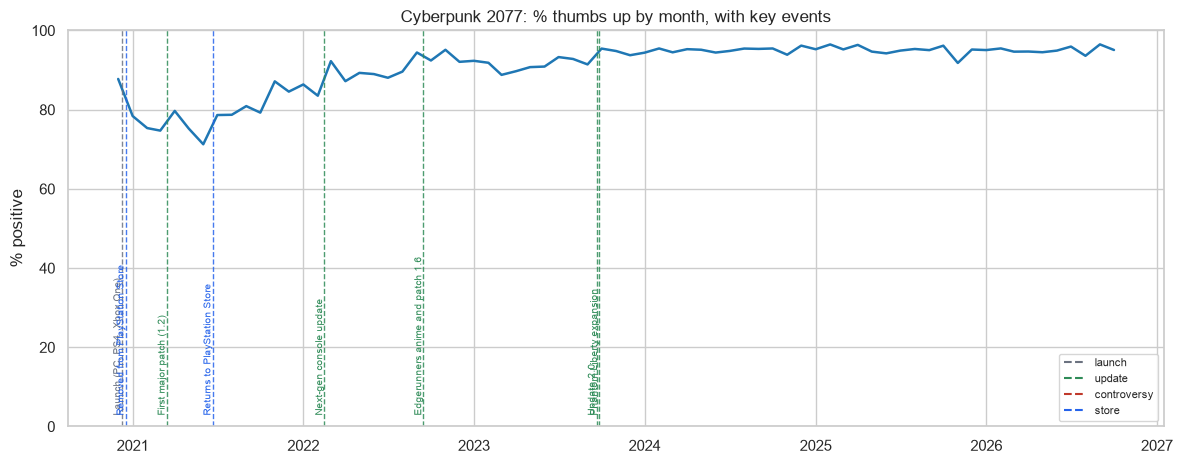

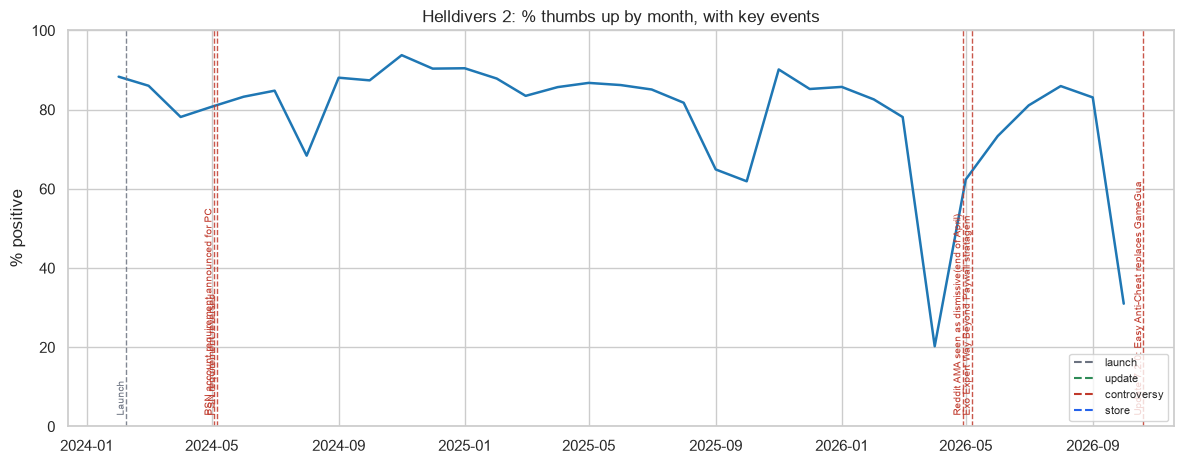

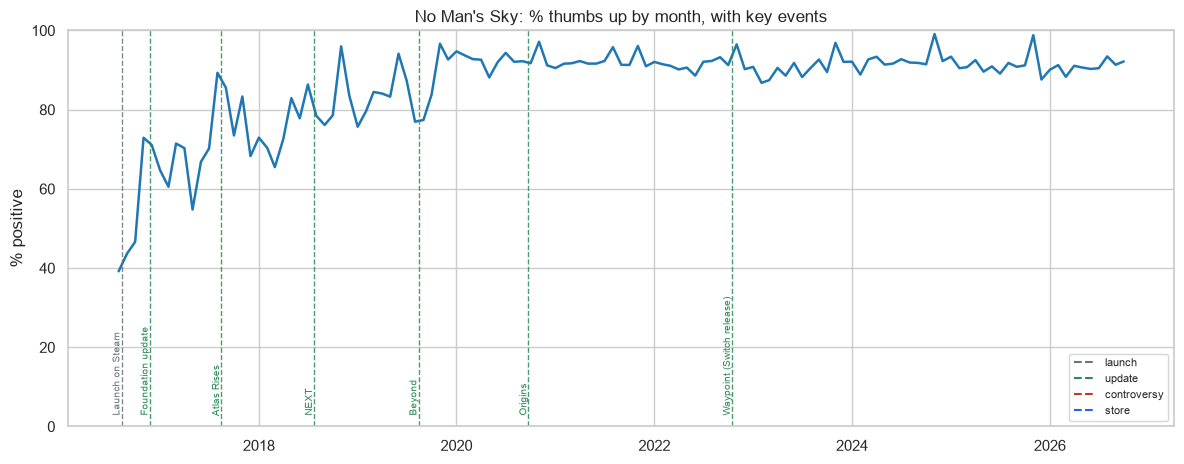

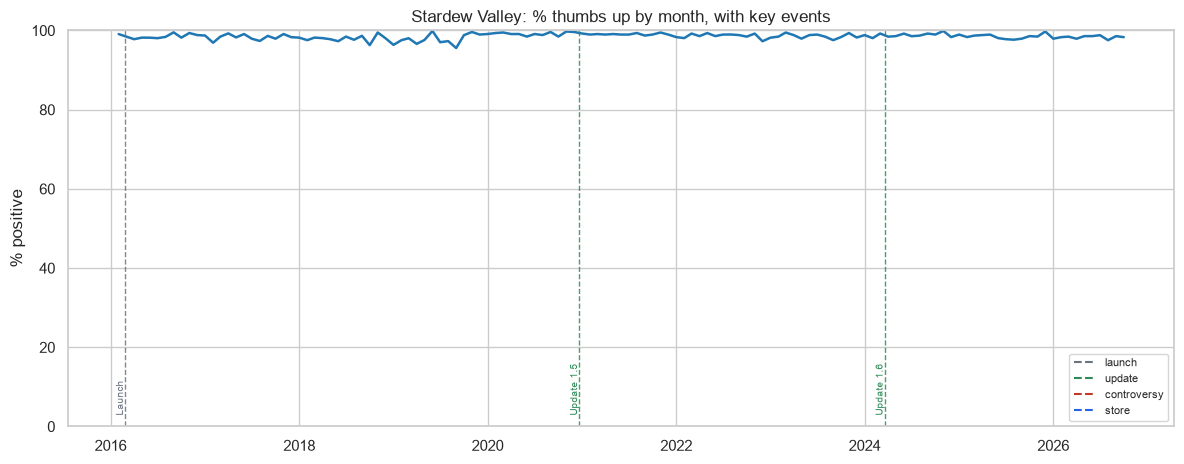

In [14]:
monthly = (df.groupby(["game", "month"])
             .agg(pct_positive=("recommended", "mean"), n=("recommended", "size")).reset_index())
monthly = monthly[monthly["n"] >= 30]
monthly["pct_positive"] *= 100

CAT_COLORS = {"launch": "#6b7280", "update": "#2e8b57", "controversy": "#c0392b", "store": "#2563eb"}

def slug(s):
    return s.replace("'", "").replace(" ", "_")

def plot_game(game):
    m = monthly[monthly["game"] == game]
    ev = events[events["game"] == game]
    fig, ax = plt.subplots(figsize=(12, 4.8))
    ax.plot(m["month"], m["pct_positive"], color="#1f77b4", lw=1.8)
    for _, e in ev.iterrows():
        x = e["date"].tz_localize(None)
        c = CAT_COLORS.get(e["category"], "gray")
        ax.axvline(x, color=c, ls="--", lw=1, alpha=0.85)
        ax.text(x, 2, " " + e["label"][:46], rotation=90, va="bottom", ha="right", fontsize=7.5, color=c)
    ax.set(title=f"{game}: % thumbs up by month, with key events", xlabel="", ylabel="% positive", ylim=(0, 100))
    handles = [plt.Line2D([0], [0], color=c, ls="--", label=k) for k, c in CAT_COLORS.items()]
    ax.legend(handles=handles, fontsize=8, loc="lower right")
    fig.tight_layout()
    fig.savefig(IMG / f"timeline_events_{slug(game)}.png", dpi=150)
    plt.show()

for game in sorted(df["game"].unique()):
    plot_game(game)

## 3. Before and after each event

Compares the share of thumbs-up reviews in the `WINDOW_DAYS` before the event with the same number of days after it, using each review's exact date. The `±95%` column is the margin of error from the sample sizes. `day_coverage` is the share of days in each window that have at least one review: when it is low, the comparison is unreliable and is marked.

In [15]:
WINDOW_DAYS = 60
MIN_COVERAGE = 0.6   # both windows need reviews on at least this share of days
MIN_N = 100          # and at least this many reviews

def window(g, start, end):
    w = g[(g["created_utc"] >= start) & (g["created_utc"] < end)]
    days = w["day"].nunique()
    return len(w), (w["recommended"].mean() * 100 if len(w) else np.nan), days

rows = []
for _, e in events.iterrows():
    g = df[df["game"] == e["game"]]
    d = e["date"]
    W = pd.Timedelta(days=WINDOW_DAYS)
    n_b, p_b, d_b = window(g, d - W, d)
    n_a, p_a, d_a = window(g, d, d + W)
    if n_b and n_a:
        se = np.sqrt((p_b / 100) * (1 - p_b / 100) / n_b + (p_a / 100) * (1 - p_a / 100) / n_a) * 100
    else:
        se = np.nan
    rows.append({
        "game": e["game"], "date": d.date(), "category": e["category"], "event": e["label"],
        "pct_before": p_b, "pct_after": p_a, "change_pp": p_a - p_b, "+-95%": 1.96 * se,
        "n_before": n_b, "n_after": n_a,
        "day_coverage_before": d_b / WINDOW_DAYS, "day_coverage_after": d_a / WINDOW_DAYS,
    })

impact = pd.DataFrame(rows)
impact["reliable"] = ((impact["n_before"] >= MIN_N) & (impact["n_after"] >= MIN_N)
                      & (impact["day_coverage_before"] >= MIN_COVERAGE)
                      & (impact["day_coverage_after"] >= MIN_COVERAGE))
impact["significant"] = impact["reliable"] & (impact["change_pp"].abs() > impact["+-95%"])
impact.round(2).to_csv(PROC / "event_impact.csv", index=False)

show = impact.drop(columns=["category"]).round({"pct_before": 1, "pct_after": 1, "change_pp": 1, "+-95%": 1,
                                                 "day_coverage_before": 2, "day_coverage_after": 2})
show

,game,date,event,pct_before,pct_after,change_pp,+-95%,n_before,n_after,day_coverage_before,day_coverage_after,reliable,significant
0,Battlefield 2042,2021-11-19,Launch,NaN,43.9,NaN,NaN,0,1553,0.00,0.08,False,False
1,Battlefield 2042,2022-06-09,Season 1: Zero Hour,30.3,51.2,21.0,3.4,1546,1540,0.72,0.48,False,False
2,Battlefield 2042,2025-05-27,Patch 8.8: Secure Boot required on supported systems,63.6,31.6,-31.9,3.7,1081,1531,0.87,0.60,True,True
3,Battlefield 2042,2025-08-07,Review bombing accelerates (Battlefield 6 Secure Boot news),33.6,45.8,12.2,3.3,1532,1733,0.62,0.47,False,False
4,Battlefield 2042,2025-10-10,Battlefield 6 launches,46.2,68.9,22.7,3.9,1912,813,0.53,1.00,False,False
5,Cyberpunk 2077,2020-12-10,"Launch (PC, PS4, Xbox One)",NaN,83.1,NaN,NaN,0,1566,0.00,0.07,False,False
6,Cyberpunk 2077,2020-12-17,Removed from PlayStation Store,NaN,83.1,NaN,NaN,0,1566,0.00,0.07,False,False
7,Cyberpunk 2077,2021-03-15,First major patch (1.2),76.9,77.2,0.3,3.0,1561,1548,0.17,0.23,False,False
8,Cyberpunk 2077,2021-06-21,Returns to PlayStation Store,77.4,75.0,-2.5,3.0,1552,1558,0.32,0.40,False,False
9,Cyberpunk 2077,2022-02-15,Next-gen console update,85.5,87.9,2.4,2.4,1547,1545,0.28,0.28,False,False


In [16]:
print(f"{impact['reliable'].sum()} of {len(impact)} events have enough data on both sides "
      f"({MIN_N}+ reviews, {MIN_COVERAGE:.0%}+ of days covered).")
impact[impact["reliable"]].sort_values("change_pp")[["game", "date", "event", "pct_before", "pct_after", "change_pp", "+-95%"]].round(1)

3 of 29 events have enough data on both sides (100+ reviews, 60%+ of days covered).


,game,date,event,pct_before,pct_after,change_pp,+-95%
2,Battlefield 2042,2025-05-27,Patch 8.8: Secure Boot required on supported systems,63.6,31.6,-31.9,3.7
22,No Man's Sky,2018-07-24,NEXT,78.5,81.2,2.7,4.9
21,No Man's Sky,2017-08-15,Atlas Rises,70.2,87.3,17.1,3.9


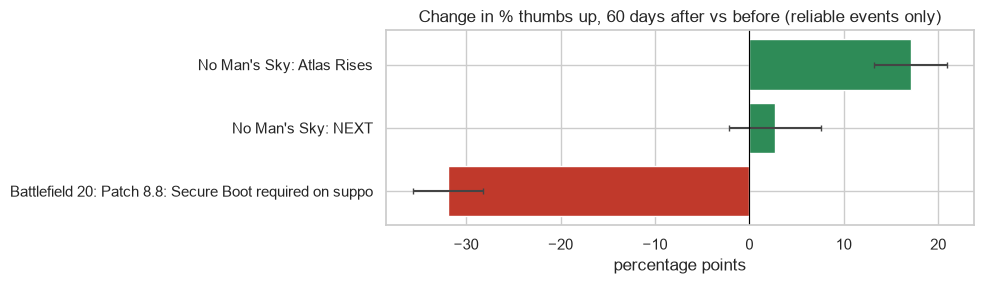

In [17]:
rel = impact[impact["reliable"] & impact["n_before"].gt(0)].copy()
if len(rel):
    rel["name"] = rel["game"].str.slice(0, 14) + ": " + rel["event"].str.slice(0, 40)
    rel = rel.sort_values("change_pp")
    fig, ax = plt.subplots(figsize=(10, max(3, 0.38 * len(rel))))
    colors = rel["category"].map(CAT_COLORS).fillna("gray")
    ax.barh(rel["name"], rel["change_pp"], xerr=rel["+-95%"], color=colors, ecolor="#444", capsize=2)
    ax.axvline(0, color="black", lw=0.8)
    ax.set(title=f"Change in % thumbs up, {WINDOW_DAYS} days after vs before (reliable events only)", xlabel="percentage points")
    fig.tight_layout()
    fig.savefig(IMG / "event_impact.png", dpi=150)
    plt.show()
else:
    print("No event has enough data on both sides. See section 1: the sample may not cover the event dates.")

## 4. Find the dips nobody told you about

Flags months where the thumbs-up share fell by `DROP_PP` points or more compared with the average of the 3 months before. Each flagged month is matched to a known event (within 45 days) or marked **unexplained**, with the words that are unusually common in that month's thumbs-down reviews to help you research what happened.

In [18]:
DROP_PP = 15

flags = []
for game, g in monthly.groupby("game"):
    g = g.sort_values("month").reset_index(drop=True)
    g["prior"] = g["pct_positive"].shift(1).rolling(3).mean()
    g["drop"] = g["prior"] - g["pct_positive"]
    for _, r in g[g["drop"] >= DROP_PP].iterrows():
        start = r["month"].tz_localize("UTC") - pd.Timedelta(days=45)
        end = r["month"].tz_localize("UTC") + pd.Timedelta(days=31)
        near = events[(events["game"] == game) & (events["date"] >= start) & (events["date"] <= end)]
        flags.append({"game": game, "month": r["month"].strftime("%Y-%m"), "pct_positive": round(r["pct_positive"], 1),
                      "prior_3mo": round(r["prior"], 1), "drop_pp": round(r["drop"], 1), "n": int(r["n"]),
                      "explained_by": "; ".join(near["label"]) if len(near) else "UNEXPLAINED"})

flags = pd.DataFrame(flags, columns=["game", "month", "pct_positive", "prior_3mo", "drop_pp", "n", "explained_by"])
flags.sort_values(["game", "month"])

,game,month,pct_positive,prior_3mo,drop_pp,n,explained_by
0,Battlefield 2042,2022-02,18.4,35.7,17.3,778,UNEXPLAINED
1,Battlefield 2042,2025-05,43.3,66.2,22.9,771,Patch 8.8: Secure Boot required on supported systems
2,Battlefield 2042,2025-06,29.4,59.4,30.1,763,Patch 8.8: Secure Boot required on supported systems
3,Helldivers 2,2025-09,64.9,84.4,19.4,775,UNEXPLAINED
4,Helldivers 2,2025-10,61.9,77.2,15.3,764,UNEXPLAINED
5,Helldivers 2,2026-04,20.3,82.2,61.9,775,Reddit AMA seen as dismissive(end of April)
6,Helldivers 2,2026-10,31.0,83.4,52.4,774,Update 7.2.0: Easy Anti-Cheat replaces GameGuard


In [19]:
def distinctive_terms(game, month, top=12, min_docs=10):
    g = df[(df["game"] == game) & (df["recommended"] == 0) & (~df["is_short"])]
    this = g[g["month"] == pd.Timestamp(month + "-01")]["review"]
    rest = g[g["month"] != pd.Timestamp(month + "-01")]["review"]
    if len(this) < 30 or len(rest) < 100:
        return "not enough thumbs-down reviews"
    cv = CountVectorizer(binary=True, ngram_range=(1, 2), stop_words="english", min_df=5)
    X = cv.fit_transform(pd.concat([this, rest]))
    a = np.asarray(X[:len(this)].sum(axis=0)).ravel()
    b = np.asarray(X[len(this):].sum(axis=0)).ravel()
    score = np.log((a + 1) / (len(this) + 2)) - np.log((b + 1) / (len(rest) + 2))
    terms = np.array(cv.get_feature_names_out())
    ok = a >= min_docs
    order = np.argsort(-np.where(ok, score, -np.inf))[:top]
    return ", ".join(terms[order][ok[order]])

unexplained = flags[flags["explained_by"] == "UNEXPLAINED"]
for _, r in unexplained.iterrows():
    print(f"{r['game']} {r['month']}  ({r['pct_positive']}% positive, was {r['prior_3mo']}%)")
    print("   unusual words in thumbs-down reviews:", distinctive_terms(r["game"], r["month"]))
if unexplained.empty:
    print("Every flagged dip is near a known event.")

Battlefield 2042 2022-02  (18.4% positive, was 35.7%)
   unusual words in thumbs-down reviews: refunds, scoreboard, broken game, scam, voice, pre ordered, ordered, refund, fans, disappointment, ea dice, chat
Helldivers 2 2025-09  (64.9% positive, was 84.4%)
   unusual words in thumbs-down reviews: restart, freeze, freezing, performance issues, freezes, size, lag, game unplayable, audio, drops, fps, frame
Helldivers 2 2025-10  (61.9% positive, was 77.2%)
   unusual words in thumbs-down reviews: pcs, guard, gameguard, hardware, coyote, freezes, stealth, grunt fantasy, load, fantasy, open, currently


Search the news for those games and months (for example "Helldivers 2 June 2026 patch"), then add what you find to `data/events.csv` and re-run.

## 5. Did the complaints change after controversies?

Shares of thumbs-down reviews (3+ words) that mention each theme in the `WINDOW_DAYS` before and after each controversy. Shown as the change in percentage points, so red means the theme became more common.

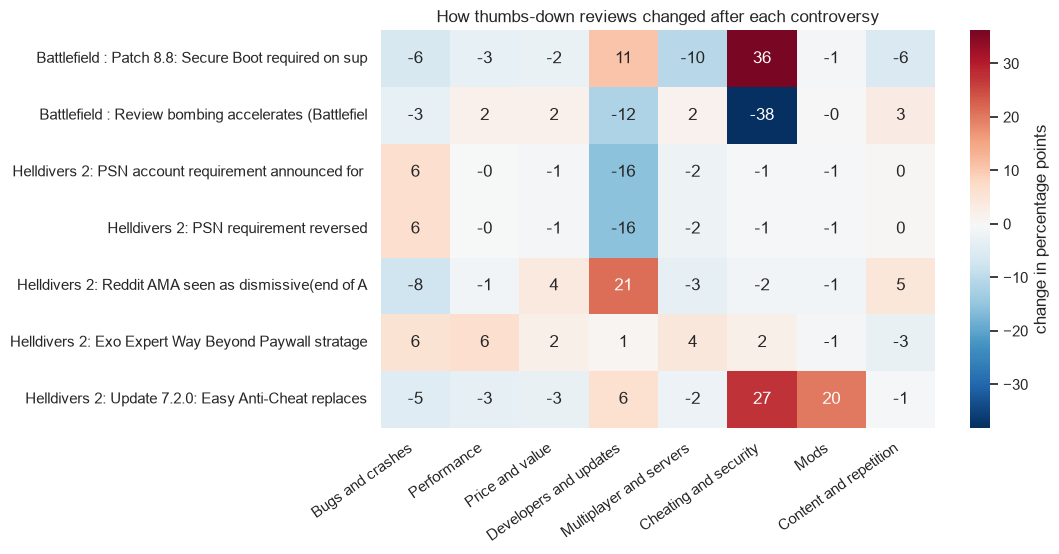

In [20]:
THEMES = {
    "Bugs and crashes":        r"\b(?:bug|bugs|buggy|crash|crashes|crashing|glitch|glitches|glitchy|broken|freez\w*|unplayable)\b",
    "Performance":             r"\b(?:fps|stutter\w*|lag|laggy|performance|optimi[sz]\w*|framerate|frame rate)\b",
    "Price and value":         r"\b(?:price|priced|money|refund\w*|worth|overpriced|expensive|waste|full price)\b",
    "Developers and updates":  r"\b(?:dev|devs|developer|developers|update|updates|patch|patches|nerf\w*|hotfix|studio|publisher)\b",
    "Multiplayer and servers": r"\b(?:server\w*|matchmaking|multiplayer|co-?op|online|disconnect\w*|netcode|lobby|login|account)\b",
    "Cheating and security":   r"\b(?:cheat\w*|hacker\w*|anti-?cheat|secure boot|kernel|easy anti)\b",
    "Mods":                    r"\b(?:mod|mods|modding|modder\w*)\b",
    "Content and repetition":  r"\b(?:boring|repetitive|repetition|grind\w*|empty|shallow|lacks?|tedious|samey|warbonds?)\b",
}

neg = df[(df["recommended"] == 0) & (~df["is_short"])].copy()
neg["text"] = neg["review"].str.lower()
for name, pat in THEMES.items():
    neg[name] = neg["text"].str.contains(pat, regex=True)

rows = []
for _, e in events[events["category"] == "controversy"].iterrows():
    g = neg[neg["game"] == e["game"]]
    W = pd.Timedelta(days=WINDOW_DAYS)
    before = g[(g["created_utc"] >= e["date"] - W) & (g["created_utc"] < e["date"])]
    after = g[(g["created_utc"] >= e["date"]) & (g["created_utc"] < e["date"] + W)]
    if len(before) < 30 or len(after) < 30:
        continue
    row = {"event": f"{e['game'][:12]}: {e['label'][:38]}", "n_before": len(before), "n_after": len(after)}
    for t in THEMES:
        row[t] = (after[t].mean() - before[t].mean()) * 100
    rows.append(row)

shift = pd.DataFrame(rows)
if len(shift):
    hm = shift.set_index("event")[list(THEMES)]
    fig, ax = plt.subplots(figsize=(11, max(2.5, 0.6 * len(hm) + 1.5)))
    sns.heatmap(hm, annot=True, fmt=".0f", cmap="RdBu_r", center=0, ax=ax,
                cbar_kws={"label": "change in percentage points"})
    ax.set(title="How thumbs-down reviews changed after each controversy", ylabel="")
    plt.xticks(rotation=35, ha="right")
    fig.tight_layout()
    fig.savefig(IMG / "complaint_shift_after_events.png", dpi=150)
    plt.show()
    shift[["event", "n_before", "n_after"]]
else:
    print("No controversy has 30+ thumbs-down reviews on both sides. Check sample coverage (section 1).")